# 04 · NLP: EDA y auditoría de datos de texto (Jarvis Calling Hiring Contest)

**Datos.** Van en `data/raw/jarvis/train.csv` (`kaggle competitions download -c jarvis-calling-hiring-contest`).
El esquema real (nombres de columnas, clases, idioma) **se verifica aquí** y las discrepancias con lo
que supone el enunciado se registran en `reports/datasheets/jarvis.md`. Sin datos, el notebook corre en
**modo demo** con un corpus sintético.

In [1]:
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.config import CFG, report_dirs, set_global_seed
from project.stats import bootstrap_ci, fmt_ci
from project.text_data import (STOPWORDS, clean_minimal, confident_learning, cross_split_duplicates, detect_columns,
                               exact_hash, flesch_reading_ease, length_percentiles, log_odds_dirichlet,
                               make_synthetic_text, mtld, near_duplicate_clusters, oov_rate, pii_scan, tokenize,
                               truncation_rate_by_class, ttr, zipf_heaps)

warnings.filterwarnings("ignore")
set_global_seed(CFG.seed)
ROOT = Path("..").resolve()
RAW = ROOT / "data/raw/jarvis/train.csv"
REAL = RAW.exists()
TAB, FIG = report_dirs(ROOT, REAL)
if REAL:
    raw = pd.read_csv(RAW)
    print("Esquema real:", raw.dtypes.to_dict()); print(raw.head(3))
    tc, yc = detect_columns(raw)
    df = raw.rename(columns={tc: "text", yc: "label"})
else:
    df = make_synthetic_text(1500, seed=CFG.seed, shortcut=0.15)
df["text"] = df["text"].astype(str); df["label"] = df["label"].astype(str)
print("Modo:", "REAL" if REAL else "DEMO — cifras no reportables", "|", len(df), "textos")

Modo: DEMO — cifras no reportables | 1500 textos


## 1. Clases, longitud, frecuencias, n-gramas y vocabulario

Razón de desbalance = 1.23; proporciones: {'class_0': 0.365, 'class_2': 0.339, 'class_1': 0.296}
(transformers no disponible: n_tokens aproximado = palabras + puntuación + 2 especiales)


,p50,p90,p95,p99
n_palabras,22.0,40.1,47.0,59.0
n_tokens,24.0,42.1,49.0,61.0


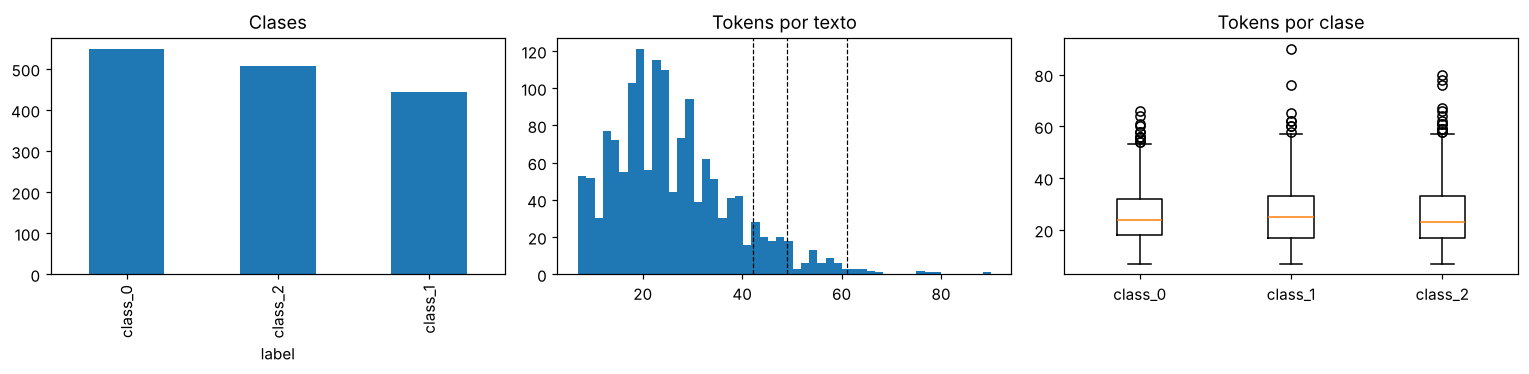

In [2]:
cnt = df.label.value_counts()
ir = cnt.max() / cnt.min()
print(f"Razón de desbalance = {ir:.2f}; proporciones: {(cnt / cnt.sum()).round(3).to_dict()}")
df["n_palabras"] = df.text.str.split().str.len()
try:   # longitud en tokens del tokenizer REAL del transformer
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    df["n_tokens"] = [len(tok(t)["input_ids"]) for t in df.text]
except Exception:
    df["n_tokens"] = df.text.map(lambda t: len(tokenize(t)) + len(re.findall(r"[^\w\s]", t)) + 2)
    print("(transformers no disponible: n_tokens aproximado = palabras + puntuación + 2 especiales)")
pct = pd.DataFrame({c: length_percentiles(df[c]) for c in ("n_palabras", "n_tokens")}).T
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
cnt.plot.bar(ax=ax[0], title="Clases"); ax[1].hist(df.n_tokens, bins=50); ax[1].set_title("Tokens por texto")
for q in (90, 95, 99): ax[1].axvline(np.percentile(df.n_tokens, q), ls="--", c="k", lw=0.8)
ax[2].boxplot([g.n_tokens for _, g in df.groupby("label")], tick_labels=list(df.groupby("label").groups)); ax[2].set_title("Tokens por clase")
plt.tight_layout(); fig.savefig(FIG / "nlp_eda_clases_longitud.png", dpi=120)
pct.round(1)

,bigramas,trigramas
class_0,"[(communication work, 47), (responsible commun...","[(project years role, 7), (communication stron..."
class_2,"[(skills role, 55), (role work, 51), (experien...","[(skills role experience, 7), (work project go..."
class_1,"[(skills role, 44), (project communication, 43...","[(pitch work years, 7), (project communication..."


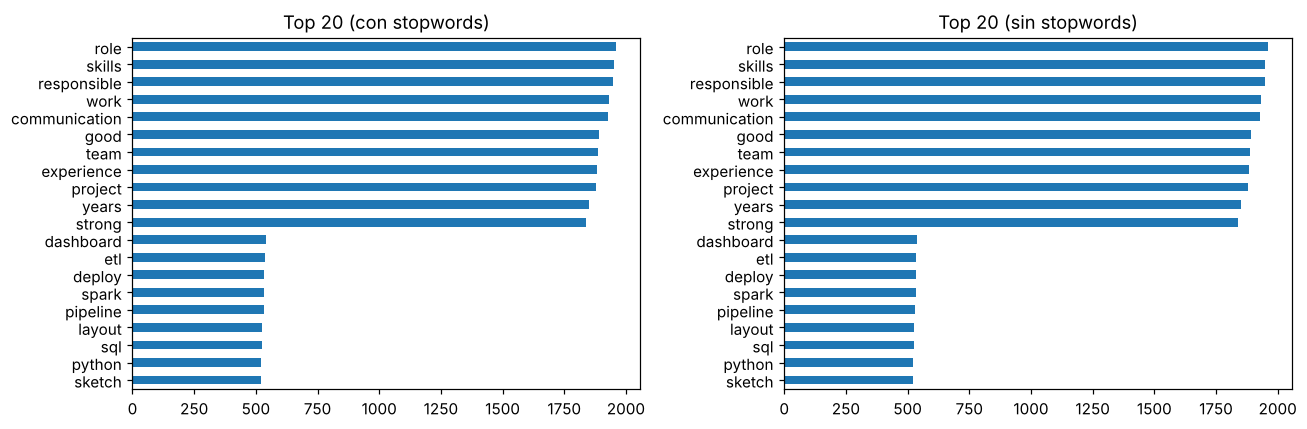

In [3]:
toks = [tokenize(t) for t in df.text]
top_all = Counter(w for t in toks for w in t).most_common(20)
top_ns = Counter(w for t in toks for w in t if w not in STOPWORDS).most_common(20)
def ngrams(ts, n): return Counter(" ".join(t[i:i + n]) for t in ts for i in range(len(t) - n + 1))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(dict(top_all)).plot.barh(ax=ax[0], title="Top 20 (con stopwords)"); pd.Series(dict(top_ns)).plot.barh(ax=ax[1], title="Top 20 (sin stopwords)")
for a in ax: a.invert_yaxis()
plt.tight_layout()
big = {k: ngrams([t for t, y in zip(toks, df.label) if y == k], 2).most_common(5) for k in cnt.index}
tri = {k: ngrams([t for t, y in zip(toks, df.label) if y == k], 3).most_common(5) for k in cnt.index}
pd.DataFrame({"bigramas": big, "trigramas": tri})

OOV train→test: {'oov_token_rate': 0.0, 'oov_type_rate': 0.0}


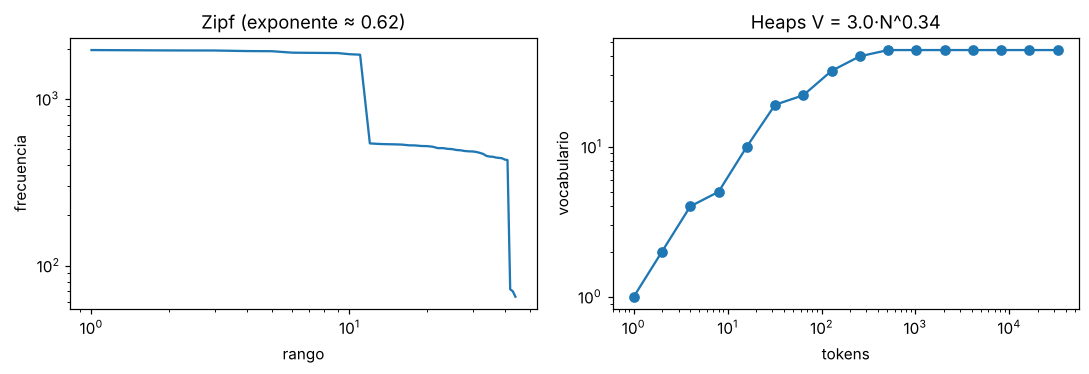

In [4]:
z = zipf_heaps(toks)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(np.arange(1, len(z["freqs"]) + 1), z["freqs"]); ax[0].set(title=f"Zipf (exponente ≈ {z['zipf_exponent']:.2f})", xlabel="rango", ylabel="frecuencia")
ax[1].loglog(z["heaps_n"], z["heaps_v"], "o-"); ax[1].set(title=f"Heaps V = {z['heaps_K']:.1f}·N^{z['heaps_beta']:.2f}", xlabel="tokens", ylabel="vocabulario")
plt.tight_layout()
from project.splits import grouped_train_val_test_split
df["dup_cluster"] = near_duplicate_clusters(df.text.tolist(), 0.8)
df["split"] = grouped_train_val_test_split(df, "dup_cluster", "label", CFG.val_frac, CFG.test_frac, CFG.seed).values
print("OOV train→test:", {k: round(v, 4) for k, v in oov_rate([toks[i] for i in np.where(df.split == "train")[0]],
                                                              [toks[i] for i in np.where(df.split == "test")[0]]).items()})

## 2. Auditoría de calidad (criterio de entrada al modelado)

### 2.1 Duplicados y casi-duplicados, y su impacto si se dejaran

Para cuantificar el impacto, se compara la F1 de TF-IDF + LR en dos particiones: una **aleatoria** que
ignora los duplicados (con fuga) y una agrupada por clúster (sin fuga). La diferencia mide cuánto
inflaría la métrica la fuga.

In [5]:
exact = df.text.map(exact_hash).duplicated(keep=False)
n_near = int((df.groupby("dup_cluster").size() > 1).sum())
conflict = df.groupby("dup_cluster").label.nunique().gt(1).sum()
print(f"Duplicados exactos: {exact.mean():.2%} | clústeres con casi-duplicados: {n_near} | "
      f"clústeres con etiquetas en conflicto: {conflict} | clústeres que cruzan particiones (agrupada): "
      f"{cross_split_duplicates(df.dup_cluster.to_numpy(), df.split.tolist())}")
from sklearn.model_selection import train_test_split
from project.models_text import tfidf_logreg
from sklearn.metrics import f1_score
dd = pd.concat([df, df.sample(frac=0.2, random_state=0).assign(text=lambda d: d.text + " .")])  # escenario con 20 % de casi-duplicados
dd["dup_cluster"] = near_duplicate_clusters(dd.text.tolist(), 0.8)
res = []
for s in range(5):
    tr, te = train_test_split(dd, test_size=0.2, stratify=dd.label, random_state=s)
    f_leak = f1_score(te.label, tfidf_logreg().fit(tr.text, tr.label).predict(te.text), average="macro")
    sp = grouped_train_val_test_split(dd, "dup_cluster", "label", 0.01, 0.2, s)
    tr2, te2 = dd[sp != "test"], dd[sp == "test"]
    f_ok = f1_score(te2.label, tfidf_logreg().fit(tr2.text, tr2.label).predict(te2.text), average="macro")
    res.append(f_leak - f_ok)
print("Inflado de F1 por fuga de casi-duplicados (escenario +20 %):", fmt_ci(*bootstrap_ci(np.array(res))))

Duplicados exactos: 0.00% | clústeres con casi-duplicados: 0 | clústeres con etiquetas en conflicto: 0 | clústeres que cruzan particiones (agrupada): 0
Inflado de F1 por fuga de casi-duplicados (escenario +20 %): 0.002 [-0.005, 0.011]


### 2.2 Ruido de etiquetas (*confident learning*)

Las probabilidades se obtienen **fuera de muestra** con CV de 5 pliegues agrupada por clúster.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold
from project.text_data import clean_standard
classes = np.unique(df.label); yi = np.searchsorted(classes, df.label)
oof = np.zeros((len(df), len(classes)))
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(df, yi, df.dup_cluster):
    m = tfidf_logreg().fit(df.text.iloc[tr].map(clean_standard), yi[tr])
    oof[te] = m.predict_proba(df.text.iloc[te].map(clean_standard))
cl = confident_learning(oof, yi)
print(f"Tasa estimada de error de etiqueta = {cl['est_noise_rate']:.3%} ({len(cl['suspects'])} sospechosos)")
df["sospechoso_etiqueta"] = False; df.loc[df.index[cl["suspects"]], "sospechoso_etiqueta"] = True
df.loc[df.sospechoso_etiqueta, ["text", "label"]].head(50).to_csv(TAB / "nlp_sospechosos_para_revision.csv")
print("Revisión manual: anote en `nlp_sospechosos_para_revision.csv` una columna `error_confirmado` (0/1); "
      "la tasa confirmada × la tasa estimada da la cota de ruido de etiqueta.")
pd.DataFrame(cl["confident_joint"], index=classes, columns=classes)

Tasa estimada de error de etiqueta = 0.000% (0 sospechosos)
Revisión manual: anote en `nlp_sospechosos_para_revision.csv` una columna `error_confirmado` (0/1); la tasa confirmada × la tasa estimada da la cota de ruido de etiqueta.


,class_0,class_1,class_2
class_0,397,0,0
class_1,0,332,0
class_2,0,0,383


### 2.3 Palabras discriminativas y atajos (log-odds con prior de Dirichlet, Monroe et al., 2008)

In [7]:
rows = []
for k in classes:
    lo = log_odds_dirichlet([t for t, y in zip(toks, df.label) if y == k], [t for t, y in zip(toks, df.label) if y != k])
    for _, r in lo.head(8).iterrows():
        rows.append(dict(clase=k, palabra=r.word, z=r.z, ic=f"[{r.ci_low:.2f}, {r.ci_high:.2f}]", n=int(r.n_a)))
disc = pd.DataFrame(rows)
# Candidatos a atajo: tokens con forma de plantilla, código, fecha o nombre propio muy discriminativos
disc["sospecha_atajo"] = disc.palabra.str.contains(r"^ref_|\d|^(mr|ms|dear|regards|sincerely)$", regex=True)
disc.to_csv(TAB / "nlp_log_odds.csv", index=False)
disc

,clase,palabra,z,ic,n,sospecha_atajo
0,class_0,dashboard,19.861568,"[2.28, 2.78]",485,False
1,class_0,deploy,19.743653,"[2.27, 2.77]",479,False
2,class_0,spark,19.743311,"[2.33, 2.85]",482,False
3,class_0,pipeline,19.682517,"[2.44, 2.98]",487,False
4,class_0,sql,19.579770,"[2.42, 2.95]",480,False
5,class_0,etl,19.576792,"[2.63, 3.22]",502,False
6,class_0,python,19.467370,"[2.48, 3.03]",480,False
7,class_0,model,19.088415,"[2.35, 2.89]",453,False
8,class_1,target,20.714417,"[2.47, 2.99]",427,False
9,class_1,quota,20.570192,"[2.41, 2.92]",418,False


### 2.4 Estructura temática

Se usan embeddings de oraciones (`sentence-transformers` si está disponible; si no, TF-IDF + SVD) y una
proyección 2D. Los tópicos se obtienen con NMF (o BERTopic en modo real) y se mide su alineación con
las clases mediante NMI. **¿Los tópicos siguen las clases o artefactos del origen?**

NMI(tópicos, clases) = 0.760


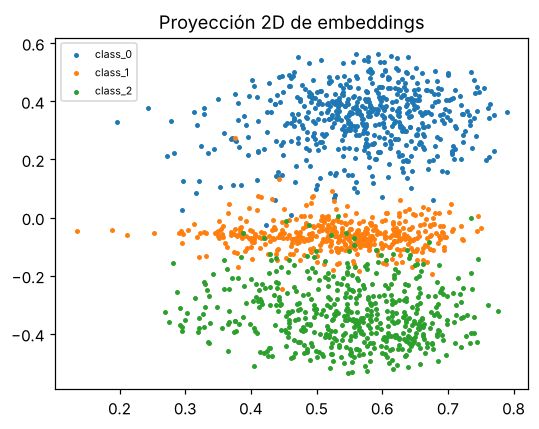

In [8]:
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score
Xtf = TfidfVectorizer(min_df=2, max_features=20000).fit_transform(df.text.map(clean_standard))
try:
    from sentence_transformers import SentenceTransformer
    E = SentenceTransformer("all-MiniLM-L6-v2").encode(df.text.tolist(), show_progress_bar=False)
    Z = TruncatedSVD(2, random_state=0).fit_transform(E) if E.shape[1] > 2 else E
except Exception:
    Z = TruncatedSVD(2, random_state=0).fit_transform(Xtf)
topics = NMF(len(classes) + 2, random_state=0, max_iter=400).fit_transform(Xtf).argmax(1)
print(f"NMI(tópicos, clases) = {normalized_mutual_info_score(df.label, topics):.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
for k in classes:
    m = (df.label == k).to_numpy(); ax.scatter(Z[m, 0], Z[m, 1], s=5, label=k)
ax.legend(fontsize=7); ax.set_title("Proyección 2D de embeddings"); plt.tight_layout()

### 2.5 Idioma, codificación, PII y atributos protegidos (o sus proxies)

In [9]:
nonascii = df.text.map(lambda t: any(ord(c) > 127 for c in t)).mean()
mojibake = df.text.str.contains("Ã|â€|ï»¿", regex=True).mean()
en = df.text.map(lambda t: np.mean([w in STOPWORDS for w in tokenize(t)]) if tokenize(t) else 0)
pii = pii_scan(df.text.tolist())
print(f"No-ASCII: {nonascii:.2%} | posible mojibake: {mojibake:.2%} | proporción media de stopwords (proxy de idioma): {en.mean():.2f}")
print("Textos con algún patrón PII:", fmt_ci(*bootstrap_ci((pii.drop(columns=['nombres_propios_aprox']).sum(1) > 0).astype(float).to_numpy())))
pii.astype(bool).mean().round(4).to_frame("proporción de textos")

No-ASCII: 0.00% | posible mojibake: 0.00% | proporción media de stopwords (proxy de idioma): 0.00
Textos con algún patrón PII: 0.000 [0.000, 0.000]


,proporción de textos
email,0.0
url,0.0
telefono,0.0
fecha,0.0
edad,0.0
terminos_genero,0.0
nombres_propios_aprox,0.0


### 2.6 Diversidad léxica y legibilidad por clase (posibles atajos)

In [10]:
df["ttr"] = [ttr(t) for t in toks]; df["mtld"] = [mtld(t) for t in toks]; df["flesch"] = df.text.map(flesch_reading_ease)
from scipy import stats as sst
lex = df.groupby("label")[["n_palabras", "ttr", "mtld", "flesch"]].median()
for c in ("n_palabras", "mtld", "flesch"):
    print(f"Kruskal–Wallis {c} por clase: p = {sst.kruskal(*[g[c].dropna() for _, g in df.groupby('label')]).pvalue:.2e}")
lex.round(2)

Kruskal–Wallis n_palabras por clase: p = 5.16e-01
Kruskal–Wallis mtld por clase: p = 8.87e-01
Kruskal–Wallis flesch por clase: p = 3.15e-12


,n_palabras,ttr,mtld,flesch
label,,,,
class_0,22.0,0.64,14.89,12.03
class_1,23.0,0.64,14.69,11.15
class_2,21.0,0.65,14.77,-0.63


## 3. Interpretación cuantitativa obligatoria

In [11]:
L95 = int(np.percentile(df.n_tokens, 95)); W95 = int(np.percentile(df.n_palabras, 95))
print(f"¿Balanceadas? razón de desbalance = {ir:.2f} → métrica primaria F1 macro; class_weight='balanced' en lineales; "
      "umbral optimizado solo en validación.")
print(f"¿Cortos o largos? p95 tokens = {L95} → max_length transformer = {min(512, int(np.ceil(L95 / 32) * 32))}; "
      f"p95 palabras = {W95} → sequence_length BiLSTM = {50 if W95 <= 50 else 100} (valor de la rejilla más cercano por encima del p95, o el máximo).")
print("Tasa de truncamiento por clase con sequence_length=100:", truncation_rate_by_class(df.n_palabras, df.label, 100).round(3).to_dict())
print(f"¿Ruido? duplicados exactos {exact.mean():.2%}; error de etiqueta estimado {cl['est_noise_rate']:.2%}; mojibake {mojibake:.2%}")
print("Riesgos de atajo identificados:", disc[disc.sospecha_atajo].palabra.unique().tolist() or "ninguno con los patrones definidos",
      "→ se verifican en el notebook 06 (ablación de atajos y CheckList).")

¿Balanceadas? razón de desbalance = 1.23 → métrica primaria F1 macro; class_weight='balanced' en lineales; umbral optimizado solo en validación.
¿Cortos o largos? p95 tokens = 49 → max_length transformer = 64; p95 palabras = 47 → sequence_length BiLSTM = 50 (valor de la rejilla más cercano por encima del p95, o el máximo).
Tasa de truncamiento por clase con sequence_length=100: {'class_0': 0.0, 'class_1': 0.0, 'class_2': 0.0}
¿Ruido? duplicados exactos 0.00%; error de etiqueta estimado 0.00%; mojibake 0.00%
Riesgos de atajo identificados: ninguno con los patrones definidos → se verifican en el notebook 06 (ablación de atajos y CheckList).
